Free Clusters on Qdrant can support serving about 1 M vectors of 768 dimensions. To calculate your needs, refer to our documentation on [Capacity Planning](https://qdrant.tech/documentation/guides/capacity-planning/).

In [1]:
import sys
import os
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(project_root)

import numpy as np
import pandas as pd
from common.const import PRODUCT_VECTOR_DB_COLLECTION, REVIEW_VECTOR_DB_COLLECTION, DEVICE, SCHEMA, TABLE_RAW_PRODUCTS, TABLE_RAW_REVIEWS
from common.helper import clickhouse_extract_data_as_df, connect_qdrant
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from qdrant_client import models
from qdrant_client.models import (
    OptimizersConfigDiff, HnswConfigDiff, SearchParams, VectorParams, BinaryQuantization,
    Distance, PointStruct, Filter, FieldCondition, Range
)
from tqdm import tqdm
import time

BATCH_SIZE = 3000
product_text_features_vector_name = "product_text_features"
user_text_features_vector_name = "user_text_features"
print(DEVICE)

qd_client = connect_qdrant()

E0000 00:00:1772533071.910754  658610 instrument.cc:563] Metric with name 'grpc.resource_quota.calls_dropped' registered more than once. Ignoring later registration.
E0000 00:00:1772533071.910802  658610 instrument.cc:563] Metric with name 'grpc.resource_quota.calls_rejected' registered more than once. Ignoring later registration.
E0000 00:00:1772533071.910805  658610 instrument.cc:563] Metric with name 'grpc.resource_quota.connections_dropped' registered more than once. Ignoring later registration.
E0000 00:00:1772533071.910808  658610 instrument.cc:563] Metric with name 'grpc.resource_quota.instantaneous_memory_pressure' registered more than once. Ignoring later registration.
E0000 00:00:1772533071.910810  658610 instrument.cc:563] Metric with name 'grpc.resource_quota.memory_pressure_control_value' registered more than once. Ignoring later registration.


cuda:0


In [ ]:
# Calculate vector memory size: memory_size = n_vectors × dim × 4 × 1.5
n_vectors = 100_000
dim = 384
vector_memory_size = n_vectors * dim * 4 * 2 / (1024**2) # Use 2 instead of 1.5 since it looks more correct

# Since we use Scalar Quantisation (INT8), it leads to 4 times reduction
# vector_memory_size = vector_memory_size / 4 # It looks like this one doesn't really do anything for SentenceTranformer
print(f"Vector Memory Size (stored on disk): {round(vector_memory_size)} MB")

# Calculate graph RAM: graph RAM ≈ n_vectors × M × 2 × 4 bytes
M = 16
graph_ram = n_vectors * M * 2 * 4 / (1024**2) + 13 # 13 is a rough estimate of the gap between theory and implemenation of Qdrant
print(f"Graph RAM (stored in RAM): {round(graph_ram)} MB")

Vector Memory Size (stored on disk): 293 MB
Graph RAM (stored in RAM): 25 MB


# 1. Create functions

In [2]:
# Create Qdrant collections
def create_qdrant_collection(collection_name, vector_name, m, ef_construct):
    # Delete the collection
    qd_client.delete_collection(collection_name=collection_name)

    # Create collection
    qd_client.create_collection(
        collection_name=collection_name,
        vectors_config={
            vector_name: VectorParams(size=384, distance=Distance.COSINE, on_disk=True) # MiniLM embedding size = 384
        },
        optimizers_config=OptimizersConfigDiff(default_segment_number=20), # https://qdrant.tech/documentation/guides/optimize/
        # Quantization: https://qdrant.tech/documentation/guides/quantization/#setting-up-quantization-in-qdrant
        # quantization_config={
        #     "scalar": {
        #         "type": "int8",
        #         "quantile": 0.99, # Exclude extreme 1% of values
        #         "always_ram": True # Keep quantized vectors in RAM
        #     }
        # },
        quantization_config=models.BinaryQuantization(
            binary=models.BinaryQuantizationConfig(
                encoding=models.BinaryQuantizationEncoding.TWO_BITS,
                always_ram=True,
            ),
        ),
        # Set HNSW parameters here: https://qdrant.tech/documentation/concepts/indexing/#vector-index
        hnsw_config=HnswConfigDiff(
            m=m,               # Default is 16
            ef_construct=ef_construct,   # Default is 100
            # full_scan_threshold=10000 # Optional
            on_disk=False
        )
    )

# 2.07 GB for 500k rows each with scalar quantization

In [3]:
# Query data

def query_products_data(n_rows, offset):
    products_query = f"""
    SELECT
        parent_asin,
        title,
        description,
        features,
        main_category,
        details,
        CAST(price AS Nullable(Float64)) AS price,
        average_rating,
        rating_number
    FROM {SCHEMA}.{TABLE_RAW_PRODUCTS}
    LIMIT {n_rows} OFFSET {offset}
    """
    return clickhouse_extract_data_as_df(products_query)

def query_reviews_data(n_rows, offset):
    reviews_query = f"""
    SELECT 
        user_id,
        parent_asin,
        title,
        text,
        rating
    FROM {SCHEMA}.{TABLE_RAW_REVIEWS}
    LIMIT {n_rows} OFFSET {offset}
    """
    return clickhouse_extract_data_as_df(reviews_query)

In [4]:
# Feature Engineering

def combine_product_text_features(row):
    text_parts = []

    if pd.notna(row['title']):
        text_parts.append((row['title'] + " ") * 1 + row['title']) # duplicate once

    if pd.notna(row['description']):
        text_parts.append(row['description'])

    if pd.notna(row['features']):
        text_parts.append(row['features'])

    if pd.notna(row['main_category']):
        text_parts.append((row['main_category'] + " ") * 2 + row['main_category'])
    
    if pd.notna(row['details']):
        text_parts.append(row['details'])

    return ' '.join(text_parts)

def group_users_by_concat_reviews(df):
    df['full_review'] = (
        df['title'].fillna('') + ' ' +
        df['text'].fillna('')
    )

    user_reviews = (
        df
        .groupby('user_id')['full_review']
        .apply(' '.join)
        .reset_index(name='all_reviews_text')
    )
    return user_reviews

In [5]:
# Vectorization
def SentenceTransformer_vectorize(df, col, model_name="sentence-transformers/all-MiniLM-L6-v2", batch_size=1024):
    model = SentenceTransformer(model_name)

    # Generate embeddings (384 dimensions)
    print("Encoding (this may take a few minutes)...")
    embeddings = model.encode(
        df[col].tolist(),
        show_progress_bar=True,
        batch_size=batch_size,
        normalize_embeddings=True,  # Normalize for cosine similarity
        device=DEVICE
    )
    return embeddings

In [6]:
# Add points to Vector DB
def add_product_points_to_qdrant(vector_name, embeddings, df, collection):
    points = [
        PointStruct(
            id=idx,
            vector={
                vector_name: embeddings[idx].tolist()
            },
            payload={
                "product_asin": row['parent_asin'],
                "title": row['title'],
                "main_category": None if pd.isna(row['main_category']) else row['main_category'],
                "price": None if pd.isna(row['price']) else row['price']
            }
        )
        for idx, row in df.iterrows()
    ]

    for i in tqdm(range(0, len(points), BATCH_SIZE), desc="Uploading product vectors..."):
        qd_client.upsert(
            collection_name=collection,
            points=points[i:i + BATCH_SIZE],
        )


def add_user_points_to_qdrant(vector_name, embeddings, df, collection):
    points = [
        PointStruct(
            id=idx,
            vector={
                vector_name: embeddings[idx].tolist()
            },
            payload={
                "user_id": row['user_id'],
                "all_reviews_text": row['all_reviews_text']
            }
        )
        for idx, row in df.iterrows()
    ]

    for i in tqdm(range(0, len(points), BATCH_SIZE), desc="Uploading user vectors..."):
        qd_client.upsert(
            collection_name=collection,
            points=points[i:i + BATCH_SIZE],
        )

In [7]:
# Performance
def qdrant_precision_at_k(embeddings, ef_search, vector_name, collection_name, k: int):
    precisions = []
    ann_time_search = []
    knn_time_search = []

    for query_vector in embeddings:
        # ANN
        start = time.time()
        ann_result = qd_client.query_points(
            collection_name=collection_name,
            query=query_vector,
            using=vector_name,
            limit=k+1,
            search_params=SearchParams(
                hnsw_ef=ef_search,
                exact=False
            )
        ).points
        ann_time_search.append(time.time() - start)
    
        # ENN
        start = time.time()
        knn_result = qd_client.query_points(
            collection_name=collection_name,
            query=query_vector,
            using=vector_name,
            limit=k+1,
            search_params=SearchParams(
                exact=True,  # Turns on the exact search mode
            ),
        ).points
        knn_time_search.append(time.time() - start)

        # We can calculate the precision@k by comparing the ids of the search results
        ann_ids = set(item.id for item in ann_result)
        knn_ids = set(item.id for item in knn_result)
        precision = (len(ann_ids.intersection(knn_ids)) - 1) / k
        precisions.append(precision)
    
    print(f"Precision@{k}: {round(np.mean(precisions), 2)} ± {round(np.std(precisions) * 2, 2)}")
    print(f"Exact Time Search: {round(np.mean(knn_time_search), 2)} seconds ± {round(np.std(knn_time_search) * 2, 2)}")
    print(f"Approximate Time Search: {round(np.mean(ann_time_search), 2)} seconds ± {round(np.std(ann_time_search) * 2, 2)}")

    return precisions, ann_time_search, knn_time_search

# 2. Create Qdrant collections

In [ ]:
# Delete the collection
qd_client.delete_collection(collection_name=PRODUCT_VECTOR_DB_COLLECTION)

# Create collection
qd_client.create_collection(
    collection_name=PRODUCT_VECTOR_DB_COLLECTION,
    vectors_config={
        "product_text_features": VectorParams(size=384, distance=Distance.COSINE, on_disk=True) # MiniLM embedding size = 384
    },
    optimizers_config=OptimizersConfigDiff(default_segment_number=4), # https://qdrant.tech/documentation/guides/optimize/
    # Quantization: https://qdrant.tech/documentation/guides/quantization/#setting-up-quantization-in-qdrant
    quantization_config={
        "scalar": {
            "type": "int8",
            "quantile": 0.99,
            "always_ram": True
        }
    },
    # Set HNSW parameters here: https://qdrant.tech/documentation/concepts/indexing/#vector-index
    hnsw_config=HnswConfigDiff(
        m=32,               # Default is 16
        ef_construct=200,   # Default is 100
        # full_scan_threshold=10000 # Optional
        on_disk=False
    )
)

In [ ]:
# Delete the collection
qd_client.delete_collection(collection_name=REVIEW_VECTOR_DB_COLLECTION)

# Create collection
qd_client.create_collection(
    collection_name=REVIEW_VECTOR_DB_COLLECTION,
    vectors_config={
        "review_text_features": VectorParams(size=384, distance=Distance.COSINE, on_disk=True) # MiniLM embedding size = 384
    },
    optimizers_config=OptimizersConfigDiff(default_segment_number=4), # https://qdrant.tech/documentation/guides/optimize/
    # Quantization: https://qdrant.tech/documentation/guides/quantization/#setting-up-quantization-in-qdrant
    quantization_config={
        "scalar": {
            "type": "int8",
            "quantile": 0.99,
            "always_ram": True
        }
    },
    # Set HNSW parameters here: https://qdrant.tech/documentation/concepts/indexing/#vector-index
    hnsw_config=HnswConfigDiff(
        m=32,               # Default is 16
        ef_construct=200,   # Default is 100
        # full_scan_threshold=10000 # Optional
        on_disk=False
    )
)

# 3. Query data

In [2]:
# Products
products_query = f"""
SELECT
    parent_asin,
    title,
    description,
    features,
    main_category,
    details,
    CAST(price AS Nullable(Float64)) AS price,
    average_rating,
    rating_number
FROM {SCHEMA}.{TABLE_RAW_PRODUCTS}
LIMIT 10000
"""
products_df = clickhouse_extract_data_as_df(products_query)

# Reviews
reviews_query = f"""
SELECT 
    user_id,
    parent_asin,
    title,
    text,
    rating
FROM {SCHEMA}.{TABLE_RAW_REVIEWS}
LIMIT 10000
"""
reviews_df = clickhouse_extract_data_as_df(reviews_query)

# 4. Feature Engineering

## Products

### Combine text features

In [17]:
cols = ['title', 'description', 'features', 'main_category', 'details']

char_counts = products_df[cols].astype(str).map(len)

summary = char_counts.agg(['mean', 'median'])
summary

,title,description,features,main_category,details
mean,113.579501,92.877316,85.62526,10.016165,181.788791
median,114.000000,4.000000,4.00000,10.000000,193.000000


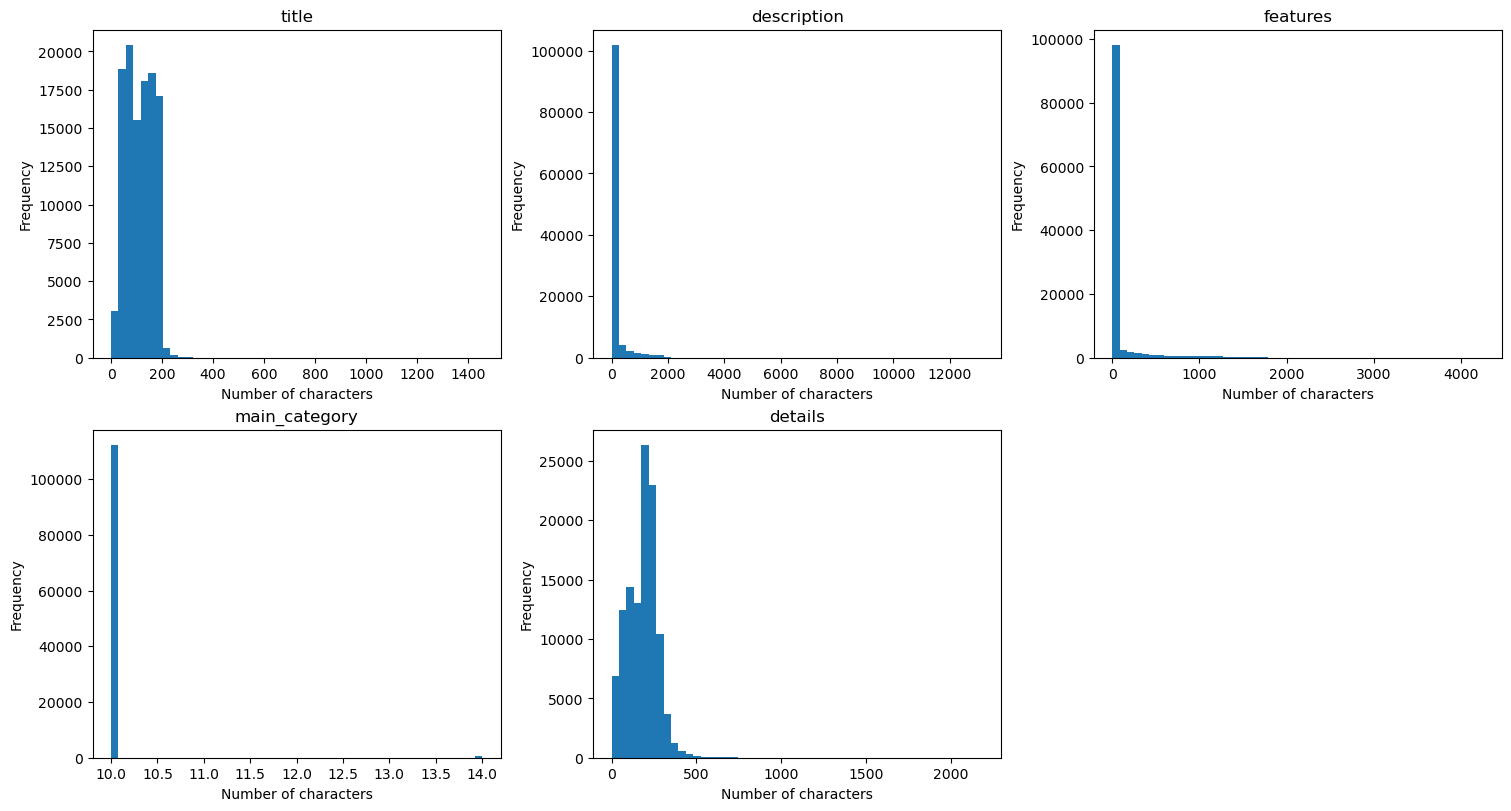

In [18]:
import matplotlib.pyplot as plt

cols = ['title', 'description', 'features', 'main_category', 'details']

# Compute character counts safely
char_counts = products_df[cols].apply(lambda c: c.fillna('').str.len())

# Create subplots
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(15, 8),
    constrained_layout=True
)

axes = axes.flatten()

for i, col in enumerate(cols):
    axes[i].hist(char_counts[col], bins=50)
    axes[i].set_title(col)
    axes[i].set_xlabel('Number of characters')
    axes[i].set_ylabel('Frequency')
    # axes[i].set_xscale('log')
    # axes[i].set_xlim(0, 1000)

# Remove unused subplot (since 5 plots in a 2x3 grid)
for j in range(len(cols), len(axes)):
    fig.delaxes(axes[j])

plt.show()

In [ ]:
products_df['combined_text'] = products_df.apply(combine_product_text_features, axis=1)

### Other methods

## Users

### Combine reviews by the same users

In [4]:
reviews_df['full_review'] = (
    reviews_df['title'].fillna('') + ' ' +
    reviews_df['text'].fillna('')
)

user_reviews = (
    reviews_df
    .groupby('user_id')['full_review']
    .apply(' '.join)
    .reset_index(name='all_reviews_text')
)
user_reviews

,user_id,all_reviews_text
0,AE222Y4WTST6BUZ4J5Y2H6QMBITQ,Lensoclean Unit The cleaning unit does a good ...
1,AE223FOBUQAUOSGVCDRABQGKGVSQ,Nivea Creme I like this even better than Prora...
2,AE224LWIR4ZDJLRKORFHMJGABP6Q,Finally a filter I can afford I was paying 50$...
3,AE22RXJGZQCC3B7QNYTZZX5WLA2Q,Not for me I was excited to try this after usi...
4,AE23L3MHWGAJGOHRLPGIG3DZT7LQ,Curly Mist I have this and like it. I wish it ...
...,...,...
9772,AHZXASNXNVVBNBY3M62GR3NVTKPQ,"Very effective, but use carefully The best way..."
9773,AHZYYJISWYKY5HUY5XA752EHPWTA,Long time Norelco user I've been using Norelco...
9774,AHZZ5BKA7P7G6WCMINCH5QL5UR6Q,Awesome Great
9775,AHZZAADBQ7AEEQW6H4JMQYLSXRQQ,Fresh smell I still don't know if this will wo...


# 5. Vectorization

## TF-IDF

In [ ]:
# Create TF-IDF vectors
vectorizer = TfidfVectorizer(
    max_features=1000,  # Reduced for faster processing
    min_df=2,
    max_df=0.8,
    ngram_range=(1, 2),
    stop_words='english'
)

tfidf_vectors = vectorizer.fit_transform(products_df['combined_text'])
vectors_dense = tfidf_vectors.toarray().astype('float32')

# Normalize for cosine similarity
vectors_normalized = normalize(vectors_dense, norm='l2')
dimension = vectors_normalized.shape[1]

## SentenceTransformer

In [5]:
model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

# Generate embeddings (384 dimensions)
print("Encoding products (this may take a few minutes)...")
product_embeddings = model.encode(
    products_df['combined_text'].tolist(),
    show_progress_bar=True,
    batch_size=128,
    normalize_embeddings=True,  # Normalize for cosine similarity
    device=DEVICE
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Encoding products (this may take a few minutes)...


Batches:   0%|          | 0/79 [00:00<?, ?it/s]

In [6]:
model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

# Generate embeddings (384 dimensions)
print("Encoding products (this may take a few minutes)...")
user_embeddings = model.encode(
    user_reviews['all_reviews_text'].tolist(),
    show_progress_bar=True,
    batch_size=128,
    normalize_embeddings=True,  # Normalize for cosine similarity
    device=DEVICE
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Encoding products (this may take a few minutes)...


Batches:   0%|          | 0/77 [00:00<?, ?it/s]

## User-item Matrix

In [ ]:
def compute_user_embeddings(reviews_df: pd.DataFrame,
                             product_vectors: np.ndarray,
                             product_ids: list,
                             weighting: str = "rating",
                             min_reviews: int = 3) -> tuple:
    """
    Represent each user as a **weighted mean** of the embeddings of products
    they have reviewed.  This captures "users who reviewed similar products".

    Parameters
    ----------
    reviews_df      : DataFrame with [user_id, parent_asin, rating]
    product_vectors : (n_products, dim) matrix – already L2 normalised
    product_ids     : list of parent_asin values matching rows of product_vectors
    weighting       : 'rating'   → weight by star rating (higher = more important)
                      'uniform'  → equal weight for all reviewed products
                      'recency'  → weight by inverse rank in review history (newest first)
    min_reviews     : drop users with fewer reviews (too sparse)

    Returns
    -------
    user_vectors : np.ndarray  shape (n_users, dim)  – L2-normalised
    user_ids     : list of user_id strings
    """
    pid_to_idx = {pid: i for i, pid in enumerate(product_ids)}

    # Filter to products we have embeddings for
    reviews = reviews_df[reviews_df["parent_asin"].isin(pid_to_idx)].copy()

    # Sort by timestamp for recency weighting
    if "timestamp" in reviews.columns:
        reviews = reviews.sort_values("timestamp", ascending=False)

    user_vectors = []
    user_ids     = []

    for user_id, grp in tqdm(reviews.groupby("user_id"), desc="Building user vectors"):
        if len(grp) < min_reviews:
            continue

        indices = [pid_to_idx[p] for p in grp["parent_asin"]]
        vecs    = product_vectors[indices]           # (k, dim)

        if weighting == "rating":
            weights = grp["rating"].values.astype(np.float32)
        elif weighting == "recency":
            # Exponential decay: most-recent review gets weight 1, older get less
            k = len(grp)
            weights = np.exp(-0.1 * np.arange(k)).astype(np.float32)
        else:  # uniform
            weights = np.ones(len(grp), dtype=np.float32)

        weights /= weights.sum()                     # normalise weights
        user_vec = (vecs * weights[:, None]).sum(0)  # weighted mean

        # L2 normalise so cosine similarity = dot product
        norm = np.linalg.norm(user_vec)
        if norm > 0:
            user_vec /= norm

        user_vectors.append(user_vec)
        user_ids.append(user_id)

    return np.array(user_vectors, dtype=np.float32), user_ids

# 6. Insert vectors

## Products

In [12]:
# Add points
points = [
    PointStruct(
        id=idx,
        vector={
            "product_text_features": product_embeddings[idx].tolist()
        },
        payload={
            "product_asin": row['parent_asin'],
            "title": row['title'],
            "main_category": row['main_category'],
            "price": row['price']
        }
    )
    for idx, row in products_df.iterrows()
]

for i in tqdm(range(0, len(points), BATCH_SIZE), desc="Loading data..."):
    qd_client.upsert(
        collection_name=PRODUCT_VECTOR_DB_COLLECTION,
        points=points[i:i + BATCH_SIZE],
    )

Loading data...: 100%|██████████| 4/4 [00:13<00:00,  3.28s/it]


## Reviews

In [13]:
# Add points
points = [
    PointStruct(
        id=idx,
        vector={
            "review_text_features": product_embeddings[idx].tolist()
        },
        payload={
            "user_id": row['user_id'],
            "all_reviews_text": row['all_reviews_text']
        }
    )
    for idx, row in user_reviews.iterrows()
]

for i in tqdm(range(0, len(points), BATCH_SIZE), desc="Loading data..."):
    qd_client.upsert(
        collection_name=REVIEW_VECTOR_DB_COLLECTION,
        points=points[i:i + BATCH_SIZE],
    )

Loading data...: 100%|██████████| 4/4 [00:16<00:00,  4.14s/it]


# 7. Similarity Query

## Products

In [ ]:
def get_similar_products(product_asin, k=5, filters=None):
    """
    Find k most similar products
    
    Args:
        product_asin: Product ID to find similar items for
        k: Number of similar products to return
        filters: Optional Qdrant filter conditions
    
    Returns:
        List of similar products with scores
    """
    # Find the product
    product_row = products_df[products_df['parent_asin'] == product_asin]
    
    if product_row.empty:
        return f"Product {product_asin} not found"
    
    product_idx = product_row.index[0]
    query_vector = product_embeddings[product_idx].tolist()
    
    # Search in Qdrant
    search_result = qd_client.search(
        collection_name=PRODUCT_VECTOR_DB_COLLECTION,
        query_vector=query_vector,
        search_params=SearchParams(
            hnsw_ef=128, # Higher value for better accuracy, lower for faster speed
            exact=False
        ),
        limit=k+1
)
    
    # Format results (skip first one - the query product itself)
    results = []
    for hit in search_result[1:]:
        results.append({
            'product_asin': hit.payload['product_asin'],
            'title': hit.payload['title'],
            'similarity_score': hit.score,
            'price': hit.payload.get('price'),
            'rating': hit.payload.get('average_rating'),
            'category': hit.payload['main_category']
        })
    
    return results


sample_product = "0005946468"
get_similar_products(sample_product)

In [47]:
def get_similar_products(product_asin, k=5, filters=None):
    """
    Find k most similar products
    
    Args:
        product_asin: Product ID to find similar items for
        k: Number of similar products to return
        filters: Optional Qdrant filter conditions
    
    Returns:
        List of similar products with scores
    """
    # Find the product
    product_row = products_df[products_df['parent_asin'] == product_asin]
    
    if product_row.empty:
        return f"Product {product_asin} not found"
    
    product_idx = product_row.index[0]
    query_vector = product_embeddings[product_idx].tolist()
    
    # Search in Qdrant
    search_result = qd_client.query_points(
        collection_name=PRODUCT_VECTOR_DB_COLLECTION,
        query=query_vector,
        limit=k+1,
        with_payload=True
    ).points
    
    # Format results (skip first one - the query product itself)
    results = []
    for hit in search_result[1:]:
        results.append({
            'product_asin': hit.payload['product_asin'],
            'title': hit.payload['title'],
            'similarity_score': hit.score,
            'price': hit.payload.get('price'),
            'rating': hit.payload.get('average_rating'),
            'category': hit.payload['main_category']
        })
    
    return results


sample_product = "0005946468"
get_similar_products(sample_product)

[{'product_asin': 'B004YT8D5W',
  'title': 'Lanolin, Manuka Honey and Collagen Facial Moisturizer',
  'similarity_score': 0.7118105,
  'price': None,
  'rating': None,
  'category': 'All Beauty'},
 {'product_asin': 'B007L4LVP6',
  'title': 'Platone Gift Pack ~ Moisturizing Face Creme 2.5oz. ~ Rejuvenating Eye Creme 1oz.',
  'similarity_score': 0.7030025,
  'price': None,
  'rating': None,
  'category': 'All Beauty'},
 {'product_asin': 'B0090007DQ',
  'title': '2 Bar Set Venezia Soapworks Oatmeal Moisturizing Soap',
  'similarity_score': 0.68477035,
  'price': None,
  'rating': None,
  'category': 'All Beauty'},
 {'product_asin': 'B0065JPB36',
  'title': 'Curel Ultra Healing Lotion 2.50 oz (Pack of 2)',
  'similarity_score': 0.6831435,
  'price': None,
  'rating': None,
  'category': 'All Beauty'},
 {'product_asin': 'B00GMOZQX4',
  'title': 'Kiss My Face Moisturizing Hand Soap, Anjou Pear 9 oz ( Pack of 3)',
  'similarity_score': 0.68036556,
  'price': None,
  'rating': None,
  'categor

## Users

In [48]:
def get_similar_users(user_id, k=5, filters=None):
    # Find the product
    user_row = user_reviews[user_reviews['user_id'] == user_id]
    
    if user_row.empty:
        return f"User {user_id} not found"
    
    user_idx = user_row.index[0]
    query_vector = user_embeddings[user_idx].tolist()
    
    # Search in Qdrant
    search_result = qd_client.query_points(
        collection_name=REVIEW_VECTOR_DB_COLLECTION,
        query=query_vector,
        limit=k+1,
        with_payload=True
    ).points
    
    # Format results (skip first one - the query product itself)
    results = []
    for hit in search_result[1:]:
        results.append({
            'user_id': hit.payload['user_id'],
            'all_reviews_text': hit.payload['all_reviews_text'],
        })
    
    return results


sample_user = "AHZUTZHOVD24ZMVRDAPDGJ22I7GQ"
get_similar_users(sample_user)

[{'user_id': 'AH3ECWOIFNOUB4BWAYBYC3Z4KFDQ',
  'all_reviews_text': 'Five Stars This works very well on areas of pain'},
 {'user_id': 'AFINYPC2ES62BZJ5ZUXS5SAM7F6Q',
  'all_reviews_text': 'Amazing This is great for aches and pains.  Amazing product.  Would highly recommend this product to anyone in need of muscle relief.'},
 {'user_id': 'AHVMNUYCMLPJIGPR7BKLLJLX57PQ',
  'all_reviews_text': "This oil is awesome for aches and pains This oil is awesome for aches and pains.  I rub it on the area and really feel relief pretty quickly.  This was recommended by a friend in another state and of course no one in my area carried it in their stores.  Amazon to the rescue.  Great price and amazon service means you can't go wrong."},
 {'user_id': 'AE5RVC7ATBDAWSS6I6UKTH7PMK2Q',
  'all_reviews_text': "This works Bought this for my boyfriend who has a lot of ache and pains because he does a lot of physical work.....he wore it to bed has not taken it off, and he said he has not been hurting in his shou

## Additional

In [30]:
# Example 2: Filtered similarity search (Qdrant's killer feature!)
# Find similar products within a price range
price_filter = Filter(
    must=[
        FieldCondition(
            key="price",
            range=Range(gte=10.0, lte=100.0)  # Products between $10-$100
        )
    ]
)

similar_affordable = get_similar_products(sample_product, k=10, filters=price_filter)
print(f"\n=== Similar affordable products ($10-$100) ===")
for i, product in enumerate(similar_affordable, 1):
    print(f"{i}. {product['product_asin']} - ${product['price']}")


=== Similar affordable products ($10-$100) ===
1. 2464782475 - $12.99
2. 7458592737 - $None
3. 9455523256 - $22.0
4. 9788077587 - $None
5. 0123034892 - $None
6. 957696718X - $None
7. B00005331K - $None
8. 0976651246 - $55.95
9. 6626892843 - $18.1
10. 7398671962 - $None


In [34]:
# Example 3: Search by vector directly (useful for cold-start)
def search_by_query_text(query_text, k=10):
    """Search products by text query"""
    model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
    query_vector = model.encode([query_text], normalize_embeddings=True, device=DEVICE)
    query_vector = query_vector[0].tolist()
    
    # query_vector = vectorizer.transform().toarray().astype('float32')
    # query_vector = normalize(query_vector, norm='l2')[0].tolist()
    
    # Search in Qdrant
    search_result = qd_client.query_points(
        collection_name=SEMANTIC_VECTOR_DB_COLLECTION,
        query=query_vector,
        limit=k+1,
        with_payload=True
    ).points
    
    results = []
    for hit in search_result:
        results.append({
            'product_asin': hit.payload['product_asin'],
            'title': hit.payload['title'],
            'similarity_score': hit.score,
            'price': hit.payload.get('price'),
            'rating': hit.payload.get('average_rating'),
            'category': hit.payload['main_category']
        })
    
    return results

search_by_query_text("wireless headphones bluetooth", k=5)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[{'product_asin': '1741666929',
  'title': 'Workout Headphones by Arena Essentials',
  'similarity_score': 0.3633049,
  'price': None,
  'rating': None,
  'category': 'All Beauty'},
 {'product_asin': '0966068432',
  'title': 'Workout Headphones by Arena Essentials',
  'similarity_score': 0.35651377,
  'price': None,
  'rating': None,
  'category': 'All Beauty'},
 {'product_asin': '0984893229',
  'title': 'Workout Headphones by Arena Essentials',
  'similarity_score': 0.28893852,
  'price': None,
  'rating': None,
  'category': 'All Beauty'},
 {'product_asin': '0692508988',
  'title': 'The Listening Cards',
  'similarity_score': 0.17749594,
  'price': None,
  'rating': None,
  'category': 'All Beauty'},
 {'product_asin': '0124784577',
  'title': 'WOW Organics Apple Cider Vinegar Shampoo - 300 mL',
  'similarity_score': 0.16796887,
  'price': None,
  'rating': None,
  'category': 'All Beauty'},
 {'product_asin': '8674394329',
  'title': 'BHRINGRAJ POWDER 100% USDA CERTIFIED ORGANIC - 100

# 8. Iteratively load and push vectorized data

In [8]:
M = 8
ef_construction = 50

create_qdrant_collection(
    collection_name=PRODUCT_VECTOR_DB_COLLECTION,
    vector_name=product_text_features_vector_name,
    m=M,
    ef_construct=ef_construction
)

create_qdrant_collection(
    collection_name=REVIEW_VECTOR_DB_COLLECTION,
    vector_name=user_text_features_vector_name,
    m=M,
    ef_construct=ef_construction
)

n_rows_products = 500_000
n_rows_reviews = n_rows_products
product_query_offset = 0
review_query_offset = 0
end_for_n_rows_reviews = n_rows_products

while True:
    # 1. Query data
    products_df = query_products_data(n_rows_products, product_query_offset)
    reviews_df = query_reviews_data(n_rows_reviews, review_query_offset)

    # 2. Feature engineering
    products_df['combined_text'] = products_df.apply(combine_product_text_features, axis=1)
    user_reviews = group_users_by_concat_reviews(reviews_df)

    # 3. Vectorize & push to Qdrant
    ### Products
    product_embeddings = SentenceTransformer_vectorize(df=products_df, col="combined_text")

    add_product_points_to_qdrant(
        vector_name=product_text_features_vector_name,
        embeddings=product_embeddings,
        df=products_df,
        collection=PRODUCT_VECTOR_DB_COLLECTION
    )

    ### User embeddings
    user_embeddings = SentenceTransformer_vectorize(df=user_reviews, col="all_reviews_text")
    
    add_user_points_to_qdrant(
        vector_name=user_text_features_vector_name,
        embeddings=user_embeddings,
        df=user_reviews,
        collection=REVIEW_VECTOR_DB_COLLECTION
    )

    if review_query_offset + n_rows_reviews >= end_for_n_rows_reviews:
        break

    product_query_offset += n_rows_products
    review_query_offset += n_rows_reviews

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Encoding (this may take a few minutes)...


Batches:   0%|          | 0/406 [00:00<?, ?it/s]

Uploading user vectors...: 100%|██████████| 139/139 [04:03<00:00,  1.75s/it]


# 9. Measure performance

In [11]:
random_products = ['B07484MS4G', 'B01FYDF3VI', 'B01C3PMM7S', 'B012HUTKTM', 'B075R6NQ1W', 'B08DCZGQJ5', 'B077WBYPLG', 'B001KYU8UM', 'B0919HCJDN', 'B08MQCXGJM']
query = f"""
SELECT
    parent_asin,
    title,
    description,
    features,
    main_category,
    details,
    CAST(price AS Nullable(Float64)) AS price,
    average_rating,
    rating_number
FROM {SCHEMA}.{TABLE_RAW_PRODUCTS}
WHERE parent_asin IN {tuple(random_products)}
"""
test_df = clickhouse_extract_data_as_df(query)
test_df['combined_text'] = test_df.apply(combine_product_text_features, axis=1)
test_embeddings = SentenceTransformer_vectorize(df=test_df, col="combined_text")

a, b, c = qdrant_precision_at_k(
    embeddings=test_embeddings,
    ef_search=32,
    vector_name=product_text_features_vector_name,
    collection_name=PRODUCT_VECTOR_DB_COLLECTION,
    k=10
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Encoding (this may take a few minutes)...


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Precision@10: 0.97 ± 0.13
Exact Time Search: 0.14 seconds ± 0.01
Approximate Time Search: 0.06 seconds ± 0.01


In [12]:
random_users = ['AG5JJZKUDTC5PREHPTI5NOC75M2Q', 'AFQIHDRZZ7RGRLSFKDGCYPBHHTKA', 'AFXCPSCWLOSVQZHN7FAECOYAT3RA', 'AHT6VS3G3JSA7KBOCBT6KPUCJX7A', 'AH4G4SNKSIWZNGZ5EDNJTRORKIMQ', 'AG4JLUSDCYTYSSE5SQADXOPATLTA', 'AGXVAAK6XJ7C2GUTYQEMBOGQ7JGQ', 'AGKPEXI6SAACYVXRNMICW3NKG2XA', 'AHA272AOVKWZUXL672G653A2MTIA', 'AH6X5VUV5AUGO3G55G7AL6GZ2QZQ']
query = f"""
SELECT 
    user_id,
    parent_asin,
    title,
    text,
    rating
FROM {SCHEMA}.{TABLE_RAW_REVIEWS}
WHERE user_id IN {tuple(random_users)}
"""
test_df = clickhouse_extract_data_as_df(query)
test_df = group_users_by_concat_reviews(test_df)
test_embeddings = SentenceTransformer_vectorize(df=test_df, col="all_reviews_text")

a, b, c = qdrant_precision_at_k(
    embeddings=test_embeddings,
    ef_search=32,
    vector_name=user_text_features_vector_name,
    collection_name=REVIEW_VECTOR_DB_COLLECTION,
    k=10
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Encoding (this may take a few minutes)...


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Precision@10: 0.66 ± 0.5
Exact Time Search: 0.51 seconds ± 2.28
Approximate Time Search: 0.16 seconds ± 0.18


In [13]:
a

[0.3, 0.3, 0.7, 0.7, 0.7, 0.4, 1.0, 0.6, 1.0, 0.9]

# 10. Check the current setting of a collection

In [8]:
info = qd_client.get_collection(collection_name=PRODUCT_VECTOR_DB_COLLECTION)

print(info.config.hnsw_config.m)
print(info.config.hnsw_config.ef_construct)

16
100
